# 08 — Double Q-learning 컴포넌트 조합

독립 Q1/Q2 중 하나에서 argmax, 다른 하나에서 평가하여 maximization bias를 줄이는 방법이다.
Behavior는 두 Q의 합을 기존 Selector로 샘플링한다. 업데이트 동전은 환경/행동 RNG와 별개다.
L.DoubleQ가 Q 합의 행동 선택과 교차 평가를 제공한다. 갱신 동전 RNG는 호출자가 관리한다.

### 실행 설정
`MODULARRL_FAST=1`은 CI용 FAST, 기본값은 FULL입니다. 각 Notebook은 독립 Kernel에서 실행합니다. 처음부터 Run All하면 RNG·Model·학습 상태를 다시 만듭니다.

In [1]:
from pathlib import Path
import os, sys, json
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').exists())
if str(root) not in sys.path: sys.path.insert(0, str(root))
import gymnasium as gym
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from copy import deepcopy
from collections import deque
from modular_rl import Model
from modular_rl import representations as R, estimators as E, selectors as S
from modular_rl import buffers as B, targets as T, updates as U, learners as L
from modular_rl.data import Transition, Episode
from modular_rl.dp import policy_evaluation, policy_iteration, value_iteration, uniform_policy, action_values
from notebooks.gymnasium.tutorial_utils import (frozenlake_mdp, evaluate, history, record, frozen_report, neural_report)
FAST = os.environ.get('MODULARRL_FAST', '0') == '1'  # 기본 FULL, CI는 FAST=1
SEED = 7
GAMMA = .99
np_rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
plt.close('all')
print({'mode': 'FAST' if FAST else 'FULL', 'seed': SEED, 'gamma': GAMMA, 'device': 'cpu'})

{'mode': 'FAST', 'seed': 7, 'gamma': 0.99, 'device': 'cpu'}


In [2]:
env = gym.make('FrozenLake-v1', map_name='4x4', is_slippery=False, max_episode_steps=1000)
eval_env = gym.make('FrozenLake-v1', map_name='4x4', is_slippery=False, max_episode_steps=100)
N_STATES, N_ACTIONS = int(env.observation_space.n), int(env.action_space.n)
print(env.observation_space, env.action_space)
desc = env.unwrapped.desc.copy()

Discrete(16) Discrete(4)


In [3]:
representation = R.Identity()  # 정수 State Index를 유지한다.
estimator = E.TabularQ(N_STATES, N_ACTIONS)
selector = S.EpsilonGreedy(1.)
model = Model(representation, estimator, selector).double()
target_generator = T.TD0(GAMMA)
update_rule = U.TabularQ(.5)

model1 = model
model2 = Model(R.Identity(), E.TabularQ(N_STATES,N_ACTIONS)).double()
learner = L.DoubleQ(model1, model2, target_generator, update_rule, action_selector=selector)
update_rng = np.random.default_rng(SEED+2)
log = history()

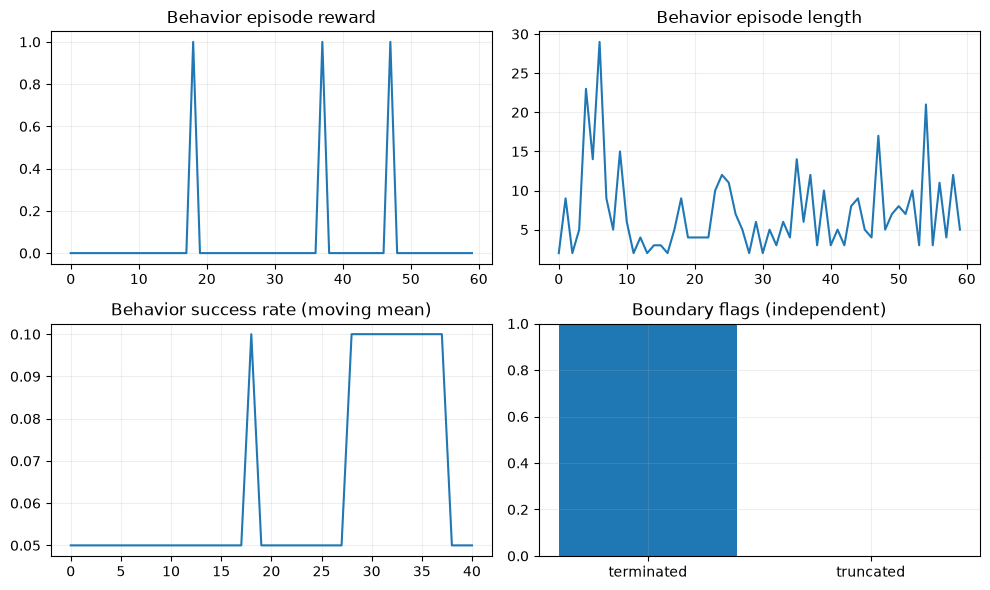

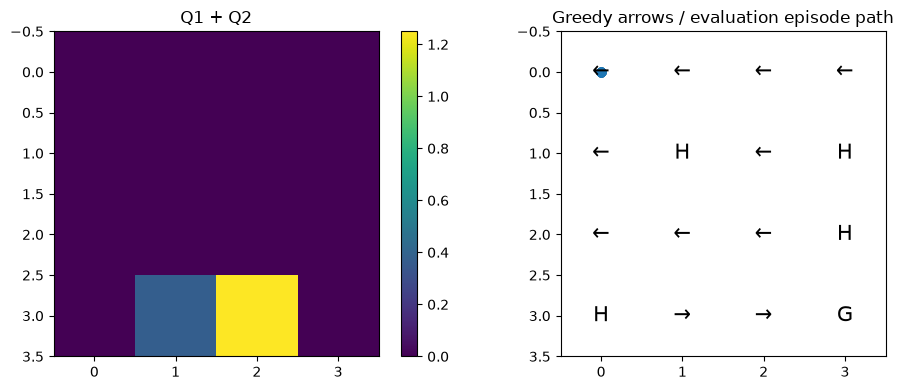

Q1 + Q2 [[0.     0.     0.     0.    ]
 [0.     0.     0.     0.    ]
 [0.     0.     0.     0.    ]
 [0.     0.     0.     0.    ]
 [0.     0.     0.     0.    ]
 [0.     0.     0.     0.    ]
 [0.     0.     0.     0.    ]
 [0.     0.     0.     0.    ]
 [0.     0.     0.     0.    ]
 [0.     0.     0.     0.    ]
 [0.     0.     0.     0.    ]
 [0.     0.     0.     0.    ]
 [0.     0.     0.     0.    ]
 [0.     0.     0.3712 0.    ]
 [0.     0.     1.25   0.    ]
 [0.     0.     0.     0.    ]]
RESULT {"environment_steps": 433, "episodes": 60, "evaluation_mean_reward": 0.0, "evaluation_success": 0.0, "terminated_rate": 1.0, "truncated_rate": 0.0}
Q1 [[0.   0.   0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.   0.   0.7

In [4]:
for episode_index in range(60 if FAST else 1500):
    selector.epsilon = max(.05, 1.-episode_index/(100 if FAST else 1000))
    observation, _ = env.reset(seed=SEED if episode_index == 0 else None)
    total, length = 0., 0
    while True:
        selected = learner.act(observation)
        next_observation, reward, terminated, truncated, _ = env.step(selected.action.item())
        reward = float(reward)  # 학습 reward의 floating 계약
        batch = Transition(observation, selected.action, reward, next_observation, terminated, truncated).to_batch()
        learner.learn(batch, update_first=bool(update_rng.random() < .5))
        total += reward; length += 1; observation = next_observation
        if terminated or truncated: break
    record(log, total, length, terminated, truncated)
model1.eval(); model2.eval()
evaluation = evaluate(eval_env, lambda state: learner.act(state, deterministic=True).action.item(), episodes=5 if FAST else 100)
table = (model1.estimator.q_table + model2.estimator.q_table).numpy()
summary = frozen_report(desc, log, table, evaluation, greedy_actions=table.argmax(-1), label='Q1 + Q2')
print('Q1', model1.estimator.q_table.numpy()); print('Q2', model2.estimator.q_table.numpy())
env.close(); eval_env.close()

### 이번 조합에서 드러난 API 특성
두 Model의 독립성을 명시적으로 유지한다. ValueOutput.q의 복수 Critic을 임의로 결합하지 않고 L.DoubleQ가 명시적 Q 합을 동일한 Selector에 전달한다.

### API 사용성 기록 — 아래 빈칸을 직접 수정해 보세요

|질문|실행 후 관찰/개선 제안|
|---|---|
|Model 생성이 자연스러운가?| |
|Learner 구성은 직관적인가?| |
|TargetGenerator를 선택하기 쉬운가?| |
|Buffer의 사용법이 일관적인가?| |
|Experience 자료형을 직접 조작할 필요가 있는가?| |
|학습 호출이 간결한가?| |
|Algorithm-specific 코드가 얼마나 필요한가?| |
|불필요한 자료형 변환이 존재하는가?| |
|API만 보고 학습 과정이 이해되는가?| |
|공용 컴포넌트로 옮길 필요가 있는 코드가 있는가?| |

FAST는 연결과 Shape 검사용이며 성능 판정이 아니다. FULL은 실제 학습용이다.
Seed 하나의 성공률로 알고리즘의 정확성을 판단하지 않는다. `terminated`와 `truncated`는
독립적인 flag이며 실제 마지막 관측을 저장한다. 아래 helper는 시각화·평가만 담당하고 학습을 숨기지 않는다.